SOURCE DENSITY CHECK
Numerical source mass = 0.999995814964167
PASS: Half-circle source has total mass approximately 1.

OPTIMAL TRANSPORT MAP CHECK
PASS: T(x) is nondecreasing.
Maximum |Phi(T(x)) - F0(x)| = 2.220446049250313e-16
PASS: Phi(T(x)) = F0(x) numerically.

TRANSPORT MAP NEAR x = +/-1

       delta         T(-1+delta)          T(1-delta)
     1.0e-01         -2.08152286          2.08152286
     1.0e-02         -3.23920842          3.23920842
     1.0e-03         -4.11958843          4.11958843
     1.0e-04         -4.85557093          4.85557093
     1.0e-06         -6.08018807          6.08018807
     1.0e-08         -7.10250780          7.10249528

As delta -> 0, the left value moves toward -infinity
and the right value moves toward +infinity.

INTERMEDIATE DENSITY MASS CHECK
t = 0.0    mass = 0.9999996345461128
t = 0.25    mass = 1.0000061296150697
t = 0.5    mass = 1.0000061480328588
t = 0.75    mass = 1.000006155598671
t = 1.0    mass = 1.000006159888183

PASS: Probabili

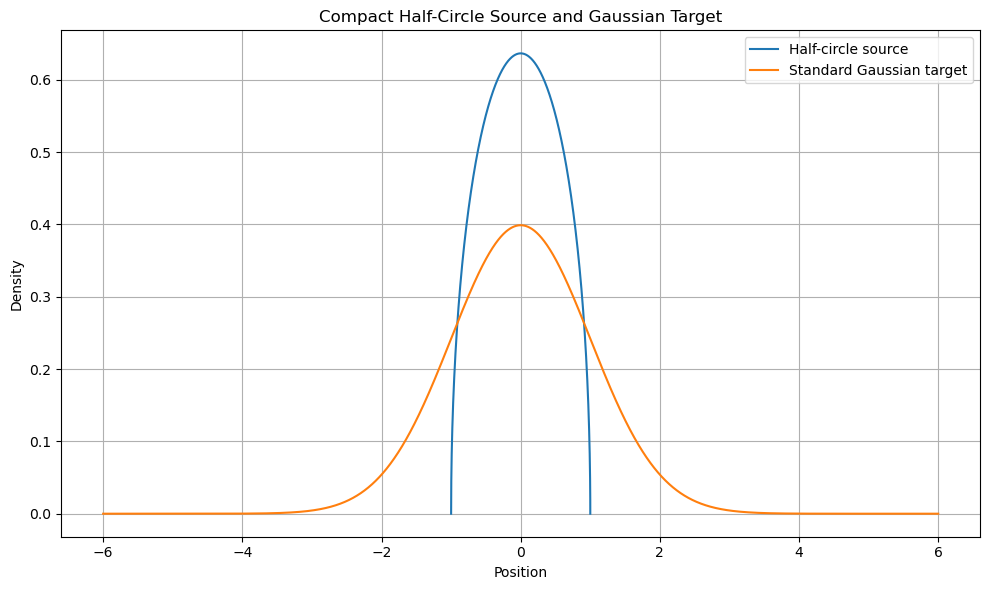

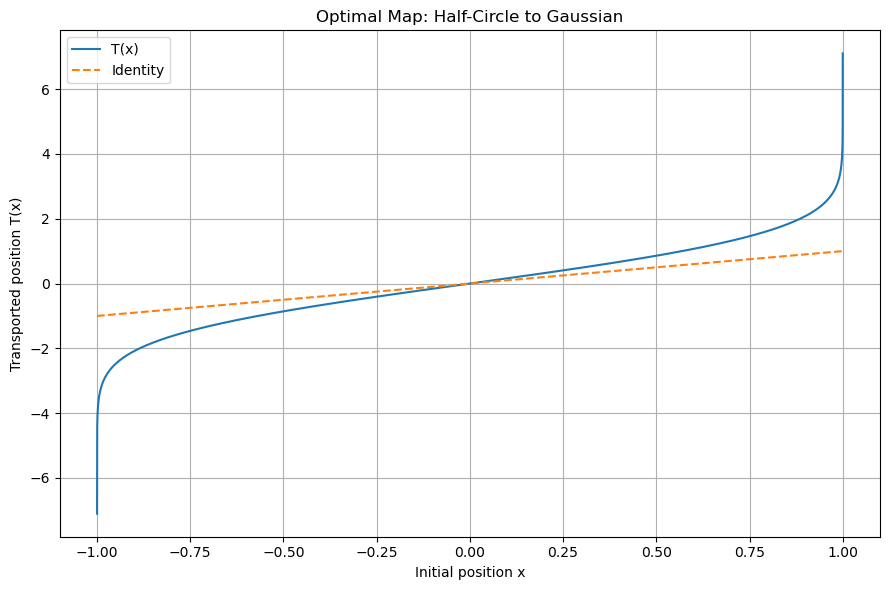

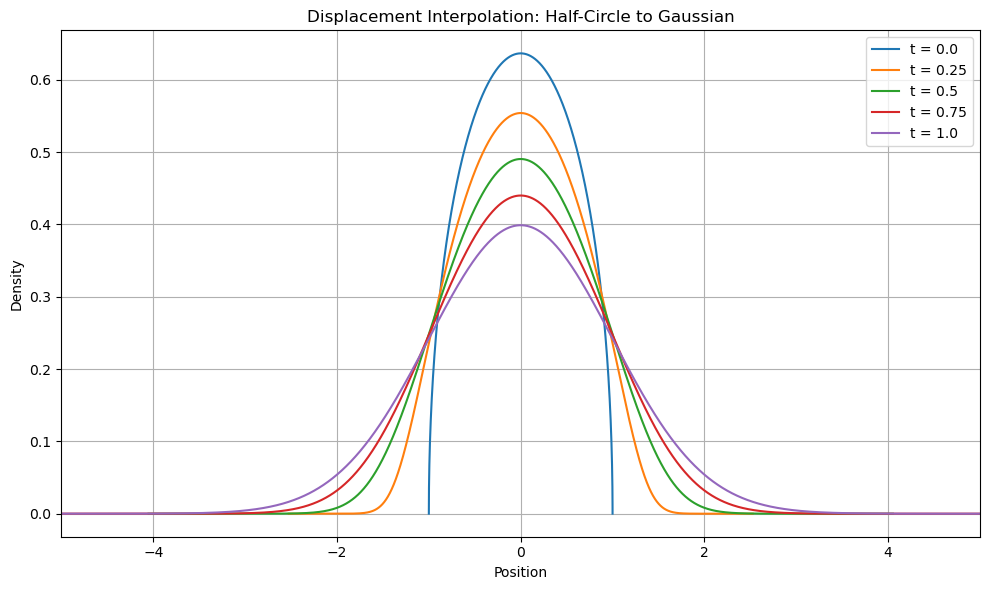

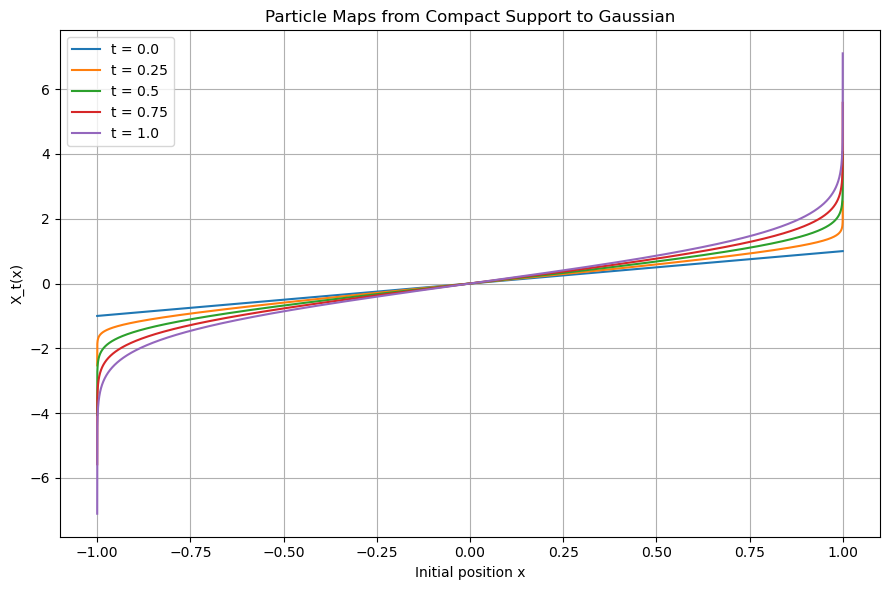


GAUSSIAN TRUNCATION STUDY

  L  Mass_Inside  Mass_Outside  Max_Map_Error_Central  Mean_Map_Error_Central
2.0     0.954500  4.550026e-02           1.106825e+00            1.135135e-01
3.0     0.997300  2.699796e-03           2.624944e-01            1.093544e-02
4.0     0.999937  6.334248e-05           9.230496e-03            2.862993e-04
5.0     0.999999  5.733031e-07           8.473410e-05            2.600351e-06
6.0     1.000000  1.973175e-09           2.916730e-07            8.950088e-09

TRUNCATION INTERPRETATION

L = 2.0
Gaussian mass captured = 0.9544997361036416
Gaussian mass omitted = 0.04550026389635842
Maximum central transport-map error = 1.106825282736637

L = 3.0
Gaussian mass captured = 0.9973002039367398
Gaussian mass omitted = 0.002699796063260207
Maximum central transport-map error = 0.2624944339863795

L = 4.0
Gaussian mass captured = 0.9999366575163338
Gaussian mass omitted = 6.334248366623996e-05
Maximum central transport-map error = 0.009230495610771605

L = 5.0
Ga

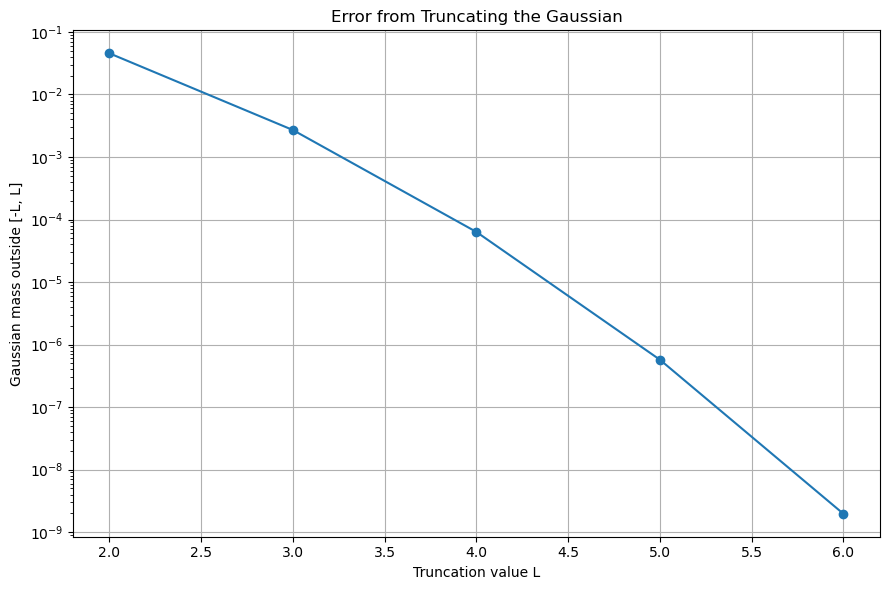

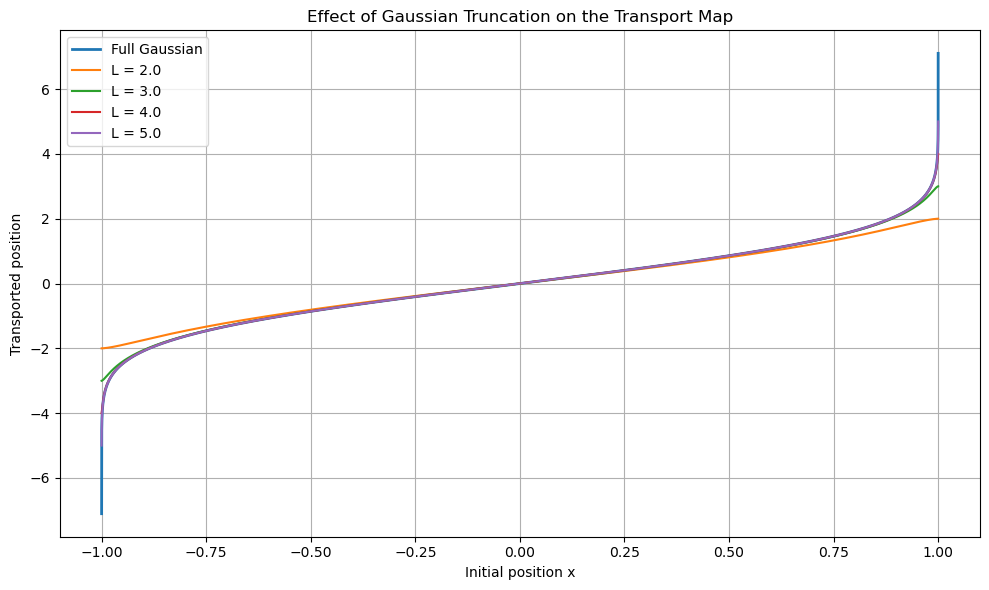


FINAL VERIFICATION
PASS: The optimal map is monotone.
PASS: Phi(T(x)) = F0(x).
PASS: T(x) diverges toward +/- infinity near the endpoints.
PASS: Intermediate densities preserve probability mass.
PASS: The t=1 density is the standard Gaussian.

Practical truncation conclusion:
L = 4 captures about 99.9937% of Gaussian mass.
L = 5 captures about 99.99994% of Gaussian mass.
Therefore L around 4 is visually reasonable,
while L around 5 gives a very accurate approximation.


In [1]:
# ============================================================
# HOMEWORK 3.2 - PART IV
# COMPACT SUPPORT TO STANDARD GAUSSIAN
#
# Compatible with NumPy 1.25
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from scipy.stats import norm


# ============================================================
# SOURCE DENSITY AND CDF
#
# rho0(x) = (2/pi) sqrt(1-x^2)
#
# F0(x)
# =
# 1/2 + (arcsin(x) + x sqrt(1-x^2))/pi
# ============================================================

def rho0_function(x):

    x = np.asarray(
        x
    )

    rho = np.zeros_like(
        x,
        dtype=float
    )

    inside = (
        np.abs(x) <= 1.0
    )

    rho[
        inside
    ] = (

        2.0
        /
        np.pi

        *

        np.sqrt(

            np.clip(

                1.0
                -
                x[inside]**2,

                0.0,

                None
            )
        )
    )

    return rho


def F0_function(x):

    x = np.asarray(
        x
    )

    F = np.zeros_like(
        x,
        dtype=float
    )

    F[
        x >= 1.0
    ] = 1.0


    inside = (

        (x > -1.0)

        &

        (x < 1.0)
    )


    xi = x[
        inside
    ]


    F[
        inside
    ] = (

        0.5

        +

        (

            np.arcsin(
                xi
            )

            +

            xi
            *
            np.sqrt(
                1.0 - xi**2
            )

        )

        /

        np.pi
    )


    return F


# ============================================================
# BASIC SOURCE GRID
# ============================================================

x = np.linspace(
    -1.0,
    1.0,
    4001
)


rho0 = rho0_function(
    x
)


F0 = F0_function(
    x
)


# ============================================================
# SOURCE MASS CHECK
# ============================================================

source_mass = np.trapz(
    rho0,
    x
)


print("=" * 72)

print(
    "SOURCE DENSITY CHECK"
)

print("=" * 72)

print(
    "Numerical source mass =",
    source_mass
)


assert abs(
    source_mass - 1.0
) < 1e-4


print(
    "PASS: Half-circle source has total mass approximately 1."
)


# ============================================================
# GAUSSIAN TARGET
# ============================================================

y_gaussian = np.linspace(
    -6.0,
    6.0,
    6001
)


rho1_gaussian = norm.pdf(
    y_gaussian
)


F1_gaussian = norm.cdf(
    y_gaussian
)


# ============================================================
# TRANSPORT GRID
#
# Do NOT use x = +/-1 exactly because
#
# F0(-1) = 0  -> norm.ppf(0) = -infinity
# F0( 1) = 1  -> norm.ppf(1) = +infinity
# ============================================================

EPS_X = 1e-8


x_particles = np.linspace(
    -1.0 + EPS_X,
    1.0 - EPS_X,
    20001
)


rho0_particles = rho0_function(
    x_particles
)


u = F0_function(
    x_particles
)


# Additional safety against floating-point rounding

u = np.clip(
    u,
    1e-14,
    1.0 - 1e-14
)


# ============================================================
# OPTIMAL TRANSPORT MAP
#
# T(x) = Phi^{-1}(F0(x))
# ============================================================

T = norm.ppf(
    u
)


# ============================================================
# TRANSPORT MAP CHECKS
# ============================================================

print()

print("=" * 72)

print(
    "OPTIMAL TRANSPORT MAP CHECK"
)

print("=" * 72)


assert np.all(
    np.diff(T) >= -1e-12
)


print(
    "PASS: T(x) is nondecreasing."
)


# Pushforward identity

Phi_of_T = norm.cdf(
    T
)


pushforward_error = np.max(

    np.abs(

        Phi_of_T

        -

        u
    )
)


print(
    "Maximum |Phi(T(x)) - F0(x)| =",
    pushforward_error
)


assert pushforward_error < 1e-12


print(
    "PASS: Phi(T(x)) = F0(x) numerically."
)


# ============================================================
# ENDPOINT BEHAVIOR
# ============================================================

deltas = np.array([
    1e-1,
    1e-2,
    1e-3,
    1e-4,
    1e-6,
    1e-8
])


print()

print("=" * 72)

print(
    "TRANSPORT MAP NEAR x = +/-1"
)

print("=" * 72)

print()

print(
    f"{'delta':>12}"
    f"{'T(-1+delta)':>20}"
    f"{'T(1-delta)':>20}"
)


for delta in deltas:

    x_left = (
        -1.0
        +
        delta
    )

    x_right = (
        1.0
        -
        delta
    )


    u_left = F0_function(
        np.array([
            x_left
        ])
    )[0]


    u_right = F0_function(
        np.array([
            x_right
        ])
    )[0]


    T_left = norm.ppf(
        u_left
    )


    T_right = norm.ppf(
        u_right
    )


    print(

        f"{delta:12.1e}"

        f"{T_left:20.8f}"

        f"{T_right:20.8f}"
    )


print()

print(
    "As delta -> 0, the left value moves toward -infinity"
)

print(
    "and the right value moves toward +infinity."
)


# ============================================================
# DERIVATIVE OF TRANSPORT MAP
#
# Phi(T(x)) = F0(x)
#
# phi(T(x)) T'(x) = rho0(x)
#
# Therefore
#
# T'(x) = rho0(x) / phi(T(x))
# ============================================================

gaussian_density_at_T = norm.pdf(
    T
)


T_prime = (

    rho0_particles

    /

    gaussian_density_at_T
)


assert np.all(
    T_prime > 0
)


# ============================================================
# DISPLACEMENT INTERPOLATION
#
# X_t(x) = (1-t)x + tT(x)
# ============================================================

def get_interpolated_density(
    t
):

    Xt = (

        (1.0 - t)
        *
        x_particles

        +

        t
        *
        T
    )


    Xt_prime = (

        (1.0 - t)

        +

        t
        *
        T_prime
    )


    rho_t = (

        rho0_particles

        /

        Xt_prime
    )


    return (
        Xt,
        rho_t
    )


# ============================================================
# INTERMEDIATE TIMES
# ============================================================

t_values = [
    0.0,
    0.25,
    0.50,
    0.75,
    1.0
]


density_results = {}


print()

print("=" * 72)

print(
    "INTERMEDIATE DENSITY MASS CHECK"
)

print("=" * 72)


for t in t_values:

    Xt, rho_t = get_interpolated_density(
        t
    )


    density_results[
        t
    ] = (
        Xt,
        rho_t
    )


    mass_t = np.trapz(
        rho_t,
        Xt
    )


    print(
        "t =",
        t,
        "   mass =",
        mass_t
    )


    assert abs(
        mass_t - 1.0
    ) < 1e-4


print()

print(
    "PASS: Probability mass is preserved."
)


# ============================================================
# FINAL TARGET CHECK
#
# At t=1:
#
# rho_1(T(x)) should equal phi(T(x))
# ============================================================

Xt_final, rho_final = density_results[
    1.0
]


gaussian_at_final_points = norm.pdf(
    Xt_final
)


final_density_error = np.max(

    np.abs(

        rho_final

        -

        gaussian_at_final_points
    )
)


print()

print("=" * 72)

print(
    "FINAL GAUSSIAN TARGET CHECK"
)

print("=" * 72)

print(
    "Maximum |rho_t=1 - Gaussian density| =",
    final_density_error
)


assert final_density_error < 1e-10


print()

print(
    "PASS: t=1 density agrees with the standard Gaussian."
)


# ============================================================
# PLOT 1:
# SOURCE AND GAUSSIAN TARGET
# ============================================================

plt.figure(
    figsize=(10, 6)
)


plt.plot(
    x,
    rho0,
    label="Half-circle source"
)


plt.plot(
    y_gaussian,
    rho1_gaussian,
    label="Standard Gaussian target"
)


plt.xlabel(
    "Position"
)

plt.ylabel(
    "Density"
)

plt.title(
    "Compact Half-Circle Source and Gaussian Target"
)

plt.grid(
    True
)

plt.legend()

plt.tight_layout()


plt.savefig(
    "hw32_part4_source_gaussian_target.png",
    dpi=300
)


plt.show()


# ============================================================
# PLOT 2:
# OPTIMAL TRANSPORT MAP
# ============================================================

plt.figure(
    figsize=(9, 6)
)


plt.plot(
    x_particles,
    T,
    label="T(x)"
)


plt.plot(
    x_particles,
    x_particles,
    linestyle="--",
    label="Identity"
)


plt.xlabel(
    "Initial position x"
)

plt.ylabel(
    "Transported position T(x)"
)

plt.title(
    "Optimal Map: Half-Circle to Gaussian"
)

plt.grid(
    True
)

plt.legend()

plt.tight_layout()


plt.savefig(
    "hw32_part4_transport_map.png",
    dpi=300
)


plt.show()


# ============================================================
# PLOT 3:
# INTERPOLATED DENSITIES
# ============================================================

plt.figure(
    figsize=(10, 6)
)


for t in t_values:

    Xt, rho_t = density_results[
        t
    ]


    plt.plot(
        Xt,
        rho_t,
        label=f"t = {t}"
    )


plt.xlabel(
    "Position"
)

plt.ylabel(
    "Density"
)

plt.title(
    "Displacement Interpolation: Half-Circle to Gaussian"
)

plt.xlim(
    -5,
    5
)

plt.grid(
    True
)

plt.legend()

plt.tight_layout()


plt.savefig(
    "hw32_part4_interpolated_densities.png",
    dpi=300
)


plt.show()


# ============================================================
# PLOT 4:
# DISPLACEMENT MAPS
# ============================================================

plt.figure(
    figsize=(9, 6)
)


for t in t_values:

    Xt, _ = density_results[
        t
    ]


    plt.plot(
        x_particles,
        Xt,
        label=f"t = {t}"
    )


plt.xlabel(
    "Initial position x"
)

plt.ylabel(
    "X_t(x)"
)

plt.title(
    "Particle Maps from Compact Support to Gaussian"
)

plt.grid(
    True
)

plt.legend()

plt.tight_layout()


plt.savefig(
    "hw32_part4_displacement_maps.png",
    dpi=300
)


plt.show()


# ============================================================
# TRUNCATED GAUSSIAN STUDY
#
# Target is the Gaussian conditioned on [-L,L].
#
# Its normalized CDF is
#
# F_L(y)
# =
# (Phi(y) - Phi(-L))
# /
# (Phi(L) - Phi(-L))
#
# Therefore
#
# F_L^{-1}(u)
# =
# Phi^{-1}(
# Phi(-L) + u[Phi(L)-Phi(-L)]
# )
# ============================================================

L_values = [
    2.0,
    3.0,
    4.0,
    5.0,
    6.0
]


truncation_results = []


# Compare maps on central 99.8% probability
# to avoid making endpoint divergence dominate the comparison.

central_mask = (

    (u >= 0.001)

    &

    (u <= 0.999)
)


for L in L_values:

    Phi_left = norm.cdf(
        -L
    )


    Phi_right = norm.cdf(
        L
    )


    Z = (
        Phi_right
        -
        Phi_left
    )


    missing_mass = (
        1.0
        -
        Z
    )


    T_truncated = norm.ppf(

        Phi_left

        +

        u * Z
    )


    map_difference = (

        T_truncated[
            central_mask
        ]

        -

        T[
            central_mask
        ]
    )


    max_map_error = np.max(
        np.abs(
            map_difference
        )
    )


    mean_map_error = np.mean(
        np.abs(
            map_difference
        )
    )


    truncation_results.append({

        "L":
            L,

        "Mass_Inside":
            Z,

        "Mass_Outside":
            missing_mass,

        "Max_Map_Error_Central":
            max_map_error,

        "Mean_Map_Error_Central":
            mean_map_error
    })


truncation_df = pd.DataFrame(
    truncation_results
)


print()

print("=" * 72)

print(
    "GAUSSIAN TRUNCATION STUDY"
)

print("=" * 72)

print()

print(
    truncation_df.to_string(
        index=False
    )
)


# ============================================================
# AUTOMATIC INTERPRETATION
# ============================================================

print()

print("=" * 72)

print(
    "TRUNCATION INTERPRETATION"
)

print("=" * 72)


for _, row in truncation_df.iterrows():

    print()

    print(
        "L =",
        row["L"]
    )

    print(
        "Gaussian mass captured =",
        row["Mass_Inside"]
    )

    print(
        "Gaussian mass omitted =",
        row["Mass_Outside"]
    )

    print(
        "Maximum central transport-map error =",
        row["Max_Map_Error_Central"]
    )


# ============================================================
# PLOT 5:
# MISSING GAUSSIAN MASS VS L
# ============================================================

plt.figure(
    figsize=(9, 6)
)


plt.semilogy(

    truncation_df[
        "L"
    ],

    truncation_df[
        "Mass_Outside"
    ],

    marker="o"
)


plt.xlabel(
    "Truncation value L"
)

plt.ylabel(
    "Gaussian mass outside [-L, L]"
)

plt.title(
    "Error from Truncating the Gaussian"
)

plt.grid(
    True
)

plt.tight_layout()


plt.savefig(
    "hw32_part4_truncation_error.png",
    dpi=300
)


plt.show()


# ============================================================
# PLOT 6:
# FULL VS TRUNCATED TRANSPORT MAPS
# ============================================================

plt.figure(
    figsize=(10, 6)
)


plt.plot(
    x_particles,
    T,
    linewidth=2,
    label="Full Gaussian"
)


for L in [
    2.0,
    3.0,
    4.0,
    5.0
]:

    Phi_left = norm.cdf(
        -L
    )


    Z = (

        norm.cdf(L)

        -

        Phi_left
    )


    T_L = norm.ppf(

        Phi_left

        +

        u * Z
    )


    plt.plot(
        x_particles,
        T_L,
        label=f"L = {L}"
    )


plt.xlabel(
    "Initial position x"
)

plt.ylabel(
    "Transported position"
)

plt.title(
    "Effect of Gaussian Truncation on the Transport Map"
)

plt.grid(
    True
)

plt.legend()

plt.tight_layout()


plt.savefig(
    "hw32_part4_truncated_transport_maps.png",
    dpi=300
)


plt.show()


# ============================================================
# FINAL SUMMARY
# ============================================================

print()

print("=" * 72)

print(
    "FINAL VERIFICATION"
)

print("=" * 72)

print(
    "PASS: The optimal map is monotone."
)

print(
    "PASS: Phi(T(x)) = F0(x)."
)

print(
    "PASS: T(x) diverges toward +/- infinity near the endpoints."
)

print(
    "PASS: Intermediate densities preserve probability mass."
)

print(
    "PASS: The t=1 density is the standard Gaussian."
)

print()

print(
    "Practical truncation conclusion:"
)

print(
    "L = 4 captures about 99.9937% of Gaussian mass."
)

print(
    "L = 5 captures about 99.99994% of Gaussian mass."
)

print(
    "Therefore L around 4 is visually reasonable,"
)

print(
    "while L around 5 gives a very accurate approximation."
)